# Dinamica a soglia fissa: tre fasi al variare di $n_P^0$, traiettorie con shock

**Parte 1** — parametri tali che nel mode `expected` sia $n^\dagger$ sia $n^*$ cadano in $(0,1)$,
col ramo sinistro sempre contrattivo (l'attrattore povero esiste sempre).

**Parte 2** — stessa cosa, ma per il mode `noshock`.

`conditions.py` controlla anche le assunzioni fondazionali (1), (2a), (11) del `.tex` — quelle
sotto cui la mappa piecewise-affine (quindi `dynamics.update_wealth`) è davvero la scelta che massimizza utility. Con i parametri di default di `parameters.py`, la condizione (11)
risulta violata — la calibrazione qui sotto ne tiene conto (serve alzare `A_up_bar`).

In [1]:
import sys
sys.path.append("/Users/sofiacattaneo/tesi-inequality/src")

In [2]:
import numpy as np
import matplotlib.pyplot as plt

import parameters as _par
from conditions import *
from conditions import _get_productivities   # non esportata da "import *" (nome con underscore)
from functions import *
from distributions import *
from dynamics import *
from simulations_shock import simulate_shock

np.random.seed(0)


## Funzioni di supporto

- `initial_dist_targeted(n_p_0, xF)`: distribuzione iniziale che realizza **esattamente** (a meno
  di arrotondamento) la frazione `n_p_0` richiesta: un gruppo uniforme sotto $x^F$, uno sopra .
- `gini(x)`: coefficiente di Gini della distribuzione di ricchezza corrente.
- `x_P(mode, A_up_bar, Ybar, ...)`: valore dell'attrattore povero $x^P=k/(1-a_L)$ nel mode scelto
  (non è in `conditions.py`, che caratterizza *se* l'attrattore povero esiste ma non ne calcola
  esplicitamente il valore).
- `analyze_run(...)`: dato un `history`, stampa i valori iniziali/finali di $n_P$, ricchezza
  media, deviazione standard e Gini, poi traccia le traiettorie e le istantanee della
  distribuzione. Usa automaticamente l'asse log quando il range dei valori è troppo ampio per un
  istogramma lineare leggibile

In [3]:
def initial_dist_targeted(n_p_0, xF, spread_above=1.0):
    '''Distribuzione iniziale con frazione ESATTA n_p_0 sopra xF:
    gruppo povero uniforme su [0,xF), gruppo protetto uniforme su [xF, xF*(1+spread_above)).'''
    def _dist(N):
        n_rich = int(round(n_p_0 * N))
        n_poor = N - n_rich
        parts = []
        if n_poor > 0: parts.append(np.random.uniform(0, xF, n_poor))
        if n_rich > 0: parts.append(np.random.uniform(xF, xF*(1+spread_above), n_rich))
        return np.concatenate(parts)
    return _dist


def gini(x):
    x = np.sort(np.asarray(x))
    n = len(x)
    cumx = np.cumsum(x)
    return (n + 1 - 2*np.sum(cumx)/cumx[-1]) / n


def x_P(mode, A_up_bar, Ybar, mu=None, r=None, alpha=None, gamma_up=None, q=None):
    '''Valore dell'attrattore povero x^P = k/(1-a_L) nel mode scelto.'''
    if mu    is None: mu    = _par.mu
    if r     is None: r     = _par.r
    if alpha is None: alpha = _par.alpha
    _, _, Aup = _get_productivities(mode, 1.0, A_up_bar, gamma_up=gamma_up, q=q)
    k   = (1-alpha)*Ybar
    a_L = (1-alpha)*((1+mu)*Aup - mu*(1+r))
    return k/(1-a_L)


def analyze_run(history, xF, label, snapshot_times, x_p_ref=None):
    n_p_t  = np.array([np.mean(h > xF) for h in history])
    X_t    = np.array([np.mean(h) for h in history])
    std_t  = np.array([np.std(h) for h in history])
    gini_t = np.array([gini(h) for h in history])

    print(f"── {label} ──")
    print(f"  n_p:     iniziale={n_p_t[0]:.4f}   finale={n_p_t[-1]:.4f}")
    print(f"  mean(x): iniziale={X_t[0]:.4g}   finale={X_t[-1]:.4g}")
    print(f"  std(x):  iniziale={std_t[0]:.4g}   finale={std_t[-1]:.4g}")
    print(f"  Gini:    iniziale={gini_t[0]:.4f}   finale={gini_t[-1]:.4f}")

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    axes[0].plot(n_p_t)
    axes[0].set_title(r"$n_t^P$"); axes[0].set_xlabel("t"); axes[0].set_ylim(-0.02, 1.02)
    axes[1].plot(X_t); axes[1].set_yscale('log')
    axes[1].set_title(r"$\mathbf{X}_t$ (scala log)"); axes[1].set_xlabel("t")
    axes[2].plot(gini_t)
    axes[2].set_title("Coefficiente di Gini"); axes[2].set_xlabel("t"); axes[2].set_ylim(-0.02, 1.02)
    fig.suptitle(label)
    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(1, len(snapshot_times), figsize=(4.3*len(snapshot_times), 4))
    if len(snapshot_times) == 1: axes = [axes]
    for ax, t in zip(axes, snapshot_times):
        h = history[t]
        degenerate = (h.max() - h.min()) < 1e-9 * max(abs(h.mean()), 1e-12)
        use_log = (not degenerate) and h.min() > 0 and h.max() > 50*max(h.min(), 1e-9)
        if degenerate:
            ax.axvline(h.mean(), color='skyblue', linewidth=4,
                       label=f"tutta la massa qui\n(x≈{h.mean():.4g})")
            ax.axvline(xF, color='red', linestyle='--', label='$x^F$')
            if x_p_ref: ax.axvline(x_p_ref, color='blue', linestyle=':', label='$x^P$')
            ax.set_xlim(h.mean()-1, h.mean()+1)
            ax.set_xlabel("ricchezza")
        elif use_log:
            ax.hist(np.log10(h), bins=60, color='skyblue', alpha=0.85)
            ax.axvline(np.log10(xF), color='red', linestyle='--', label='$x^F$')
            if x_p_ref: ax.axvline(np.log10(x_p_ref), color='blue', linestyle='--', label='$x^P$')
            ax.set_xlabel(r"$\log_{10}(\mathrm{ricchezza})$")
        else:
            ax.hist(h, bins=60, color='skyblue', alpha=0.85)
            ax.axvline(xF, color='red', linestyle='--', label='$x^F$')
            if x_p_ref: ax.axvline(x_p_ref, color='blue', linestyle='--', label='$x^P$')
            ax.set_xlabel("ricchezza")
        ax.set_title(f"t={t}"); ax.legend(fontsize=8)
    fig.suptitle(f"{label} — istantanee della distribuzione")
    plt.tight_layout()
    plt.show()

    return dict(n_p_t=n_p_t, X_t=X_t, std_t=std_t, gini_t=gini_t)


## Parte 1 — mode `expected`

Parto dai parametri di default di `parameters.py` e cerco la modifica minima. Prima di tutto
controllo le assunzioni fondazionali (1),(2a),(11) — indipendenti da `Ybar`.

In [4]:
from conditions import check_foundational_assumptions

print("Default:")
check_foundational_assumptions(_par.A_p_bar, _par.A_up_bar)


Default:
╔══ ASSUNZIONI FONDAZIONALI (1),(2a),(11) ══╗
  E(A_p) al minimo (n_p=0) = 1.3600   E(A_up) = 1.0500   1+r = 1.0100
  (1)  E(Ap) > E(Aup) : OK
  (2a) E(Ap) > 1+r    : OK
  (11) E(Aup) > 1+r   : OK



True

In [6]:
print("Ricerca: Ybar, con A_p_bar=1.7 (default), A_up_bar=1.5")
for Ybar in [0.5, 0.3, 0.2, 0.15, 0.1, 0.05]:
    ns = n_star('expected', _par.A_p_bar, p=_par.p, gamma_p=_par.gamma_p)
    nd = n_dagger('expected', _par.A_p_bar, Ybar=Ybar, p=_par.p, gamma_p=_par.gamma_p)
    lb = left_branch_type('expected', _par.A_p_bar, _par.A_up_bar, Ybar=Ybar,
                           p=_par.p, gamma_p=_par.gamma_p, gamma_up=_par.gamma_up, q=_par.q)
    print(f"  Ybar={Ybar:4.2f}   n_dagger={nd:7.4f}   n*={ns:.4f}   ramo sinistro={lb}")


Ricerca: Ybar, con A_p_bar=1.7 (default), A_up_bar=1.5
  Ybar=0.50   n_dagger=-0.1723   n*=0.1954   ramo sinistro=poor_attractor
  Ybar=0.30   n_dagger=-0.0252   n*=0.1954   ramo sinistro=poor_attractor
  Ybar=0.20   n_dagger= 0.0483   n*=0.1954   ramo sinistro=poor_attractor
  Ybar=0.15   n_dagger= 0.0851   n*=0.1954   ramo sinistro=poor_attractor
  Ybar=0.10   n_dagger= 0.1218   n*=0.1954   ramo sinistro=poor_attractor
  Ybar=0.05   n_dagger= 0.1586   n*=0.1954   ramo sinistro=poor_attractor


`Ybar=0.1` funziona ancora (i valori di $n^\dagger,n^*$ non cambiano: non dipendono da
`A_up_bar`). Verifico con il diagnostico completo — ora include automaticamente il controllo
fondazionale.

In [7]:
print_regime_summary(A_up_bar=1.5, Ybar=0.1)


╔══ PARAMETRI CORRENTI ══╗
  p = 0.5   q = 0.5   gamma_p = 0.4   gamma_up = 0.6
  A_p_bar = 1.7   A_up_bar = 1.5   xF (F) = 0.3333333333333333


╔══ ANALISI TEORICA (valori attesi) ══╗
  n* calcolato con E[A_p] = A_p_bar*(1-p*gamma_p)*(1+n_p)
───────────────────────────────────────────────────────
 MODE: EXPECTED
───────────────────────────────────────────────────────
  Tipo ramo sinistro : poor_attractor
  Tipo ramo destro : phase_transition
  n_dagger (soglia di POSIZIONE, f_R(xF)=xF) = 0.1218  (in [0,1] )
  n*       (soglia di PENDENZA,  a_R=1)      = 0.1954  (in [0,1] )
  a_R(n_p = 0)     = 0.7210
  a_R(n_p = n*)    = 1.0000
  a_R(n_p = 1)     = 2.1490
  Regime per n_p vicino a 0 : unique_poor_attractor
  transizione vicino a n_p≈0.1228 : unique_poor_attractor  →  poor_and_rich_attractor
  transizione vicino a n_p≈0.1955 : poor_and_rich_attractor  →  poor_attractor_and_explosion

╔══ ANALISI SIMULATIVA (produttività reale) ══╗
  n* calcolato con la produttività effettiva.
  Ad ogni

In [14]:
YBAR_1     = 0.1
XF_1   = _par.xF               # F di default, non tocco F qui
ND_1   = n_dagger('expected', _par.A_p_bar, Ybar=YBAR_1, p=_par.p, gamma_p=_par.gamma_p)
NS_1   = n_star('expected', _par.A_p_bar, p=_par.p, gamma_p=_par.gamma_p)
XP_1   = x_P('expected', _par.A_up_bar, YBAR_1, gamma_up=_par.gamma_up, q=_par.q)

# soglie del mode 'shock' da solo, con GLI STESSI parametri — per confronto
ND_1_shock = n_dagger('shock', _par.A_p_bar, Ybar=YBAR_1, gamma_p=_par.gamma_p)
NS_1_shock = n_star('shock', _par.A_p_bar, gamma_p=_par.gamma_p)

print(f"n_dagger (expected) = {ND_1:.4f}   n* (expected) = {NS_1:.4f}   xF = {XF_1:.4f}   xP = {XP_1:.4f}")
print(f"n_dagger (shock)    = {ND_1_shock:.4f}   n* (shock)    = {NS_1_shock:.4f}")

N_SIM = 20000
T_SIM = 150


n_dagger (expected) = 0.1218   n* (expected) = 0.1954   xF = 0.3333   xP = 0.0579
n_dagger (shock)    = 0.4958   n* (shock)    = 0.5938


### Le simulazioni: $n_P^0$ scelto guardando le soglie `expected`, dinamica con shock veri

Comincio con gli stessi tre valori di $n_P^0$ scelti guardando $n^\dagger,n^*$ **expected**
(0.122, 0.195), poi ne aggiungo un quarto guardando le soglie **shock** (0.496, 0.594), molto più
alte, per vedere quale delle due coppie di soglie predice davvero l'esito.

── Parte 1 — n_P^0=0.06 (< n†_expected=0.122) ──
  n_p:     iniziale=0.0600   finale=0.0000
  mean(x): iniziale=0.1871   finale=0.02806
  std(x):  iniziale=0.125   finale=3.469e-18
  Gini:    iniziale=0.3648   finale=0.0000


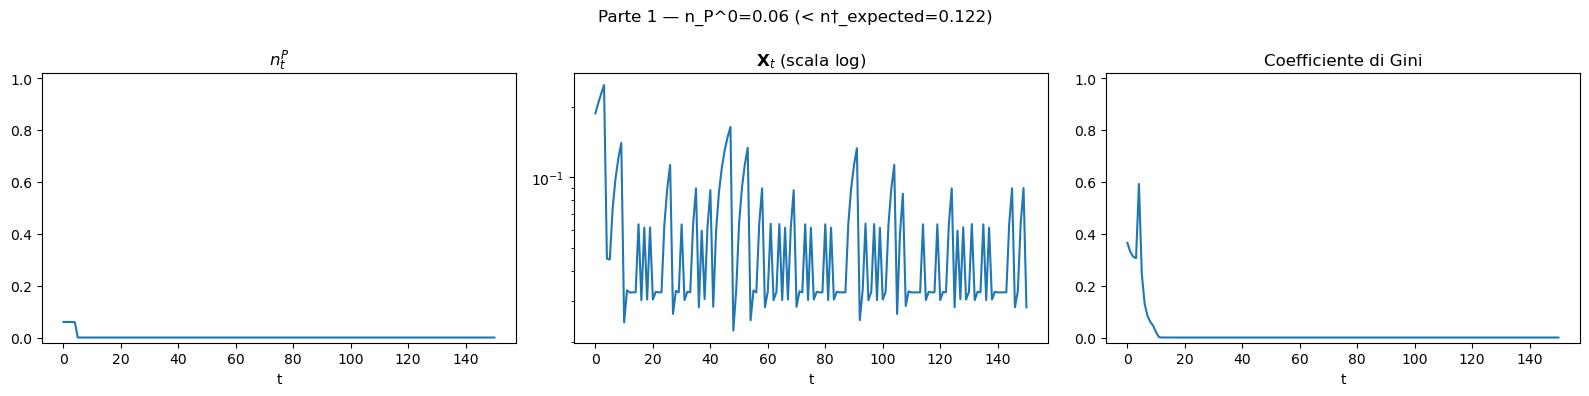

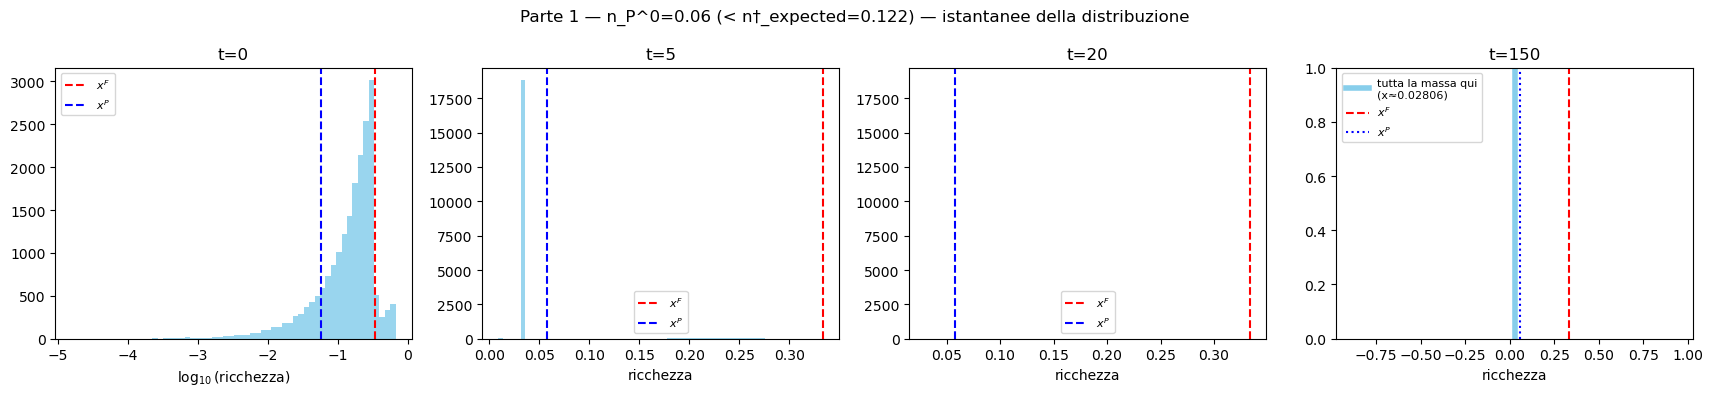

In [11]:
np.random.seed(1)
dist_1a = initial_dist_targeted(0.06, XF_1)   # < n_dagger (expected) = 0.122
history_1a = simulate_shock(dist_1a, update_wealth, T_SIM, N=N_SIM, A_p_bar=_par.A_p_bar, A_up_bar=_par.A_up_bar, Ybar=YBAR_1)
res_1a = analyze_run(history_1a, XF_1, f"Parte 1 — n_P^0=0.06 (< n†_expected={ND_1:.3f})",
                      snapshot_times=[0, 5, 20, T_SIM], x_p_ref=XP_1)


── Parte 1 — n_P^0=0.16 (tra n†,n* expected) ──
  n_p:     iniziale=0.1600   finale=0.0000
  mean(x): iniziale=0.2204   finale=0.02806
  std(x):  iniziale=0.1562   finale=3.469e-18
  Gini:    iniziale=0.3891   finale=0.0000


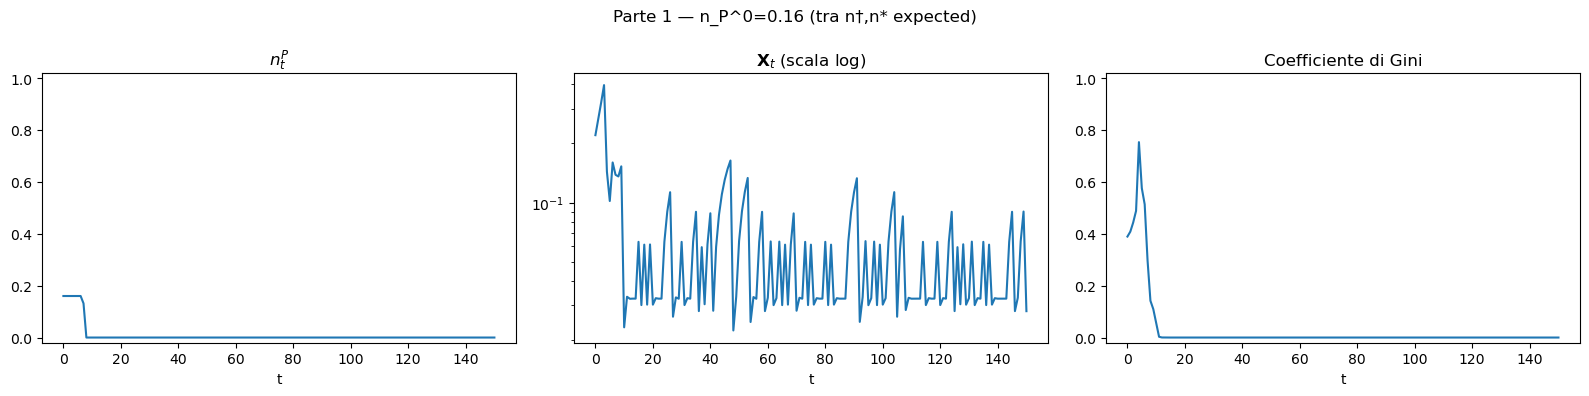

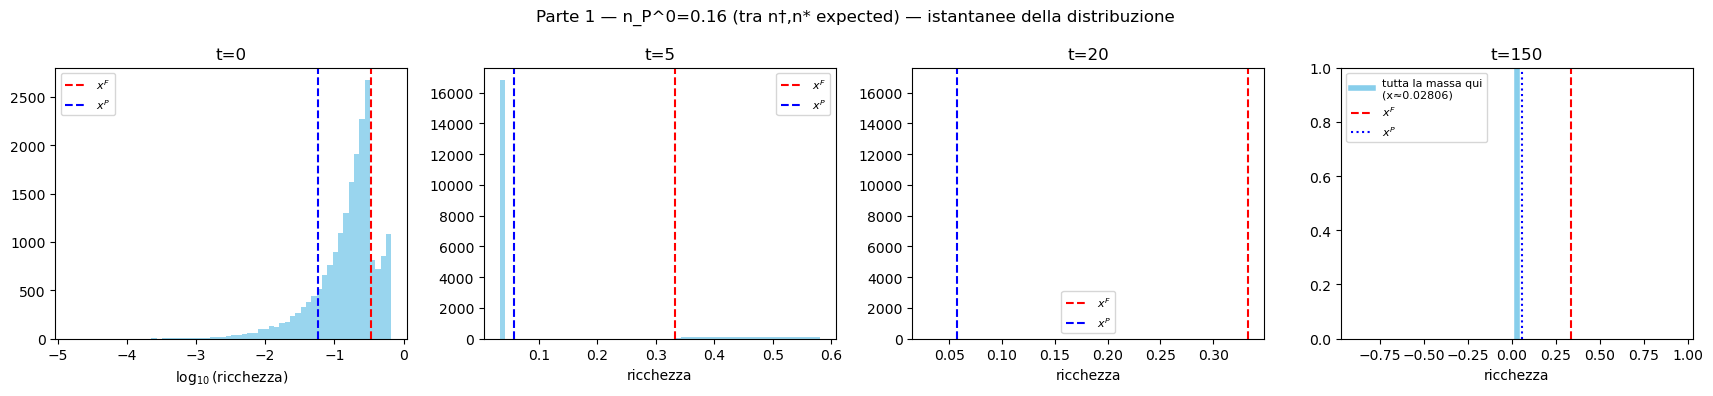

In [15]:
np.random.seed(1)
dist_1b = initial_dist_targeted(0.16, XF_1)     # tra n_dagger e n* (expected)
history_1b = simulate_shock(dist_1b, update_wealth, T_SIM, N=N_SIM, A_p_bar=_par.A_p_bar, A_up_bar=_par.A_up_bar, Ybar=YBAR_1)
res_1b = analyze_run(history_1b, XF_1, f"Parte 1 — n_P^0=0.16 (tra n†,n* expected)",
                      snapshot_times=[0, 5, 20, T_SIM], x_p_ref=XP_1)


── Parte 1 — n_P^0=0.35 (> n*_expected, ma < n†_shock=0.496) ──
  n_p:     iniziale=0.3500   finale=0.3500
  mean(x): iniziale=0.2838   finale=5.837e+04
  std(x):  iniziale=0.1864   finale=8.036e+04
  Gini:    iniziale=0.3751   finale=0.6734


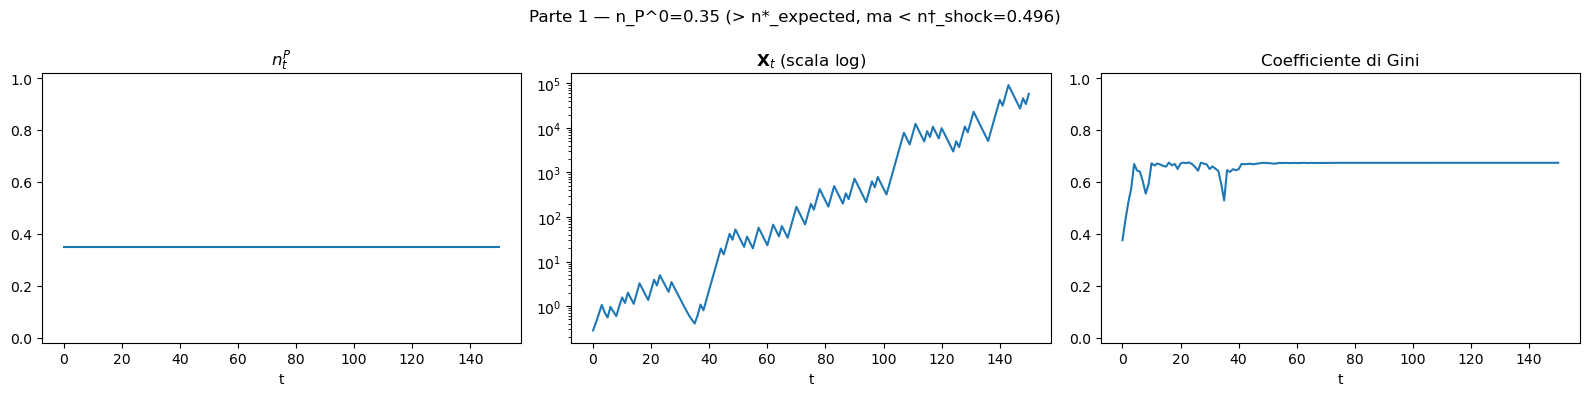

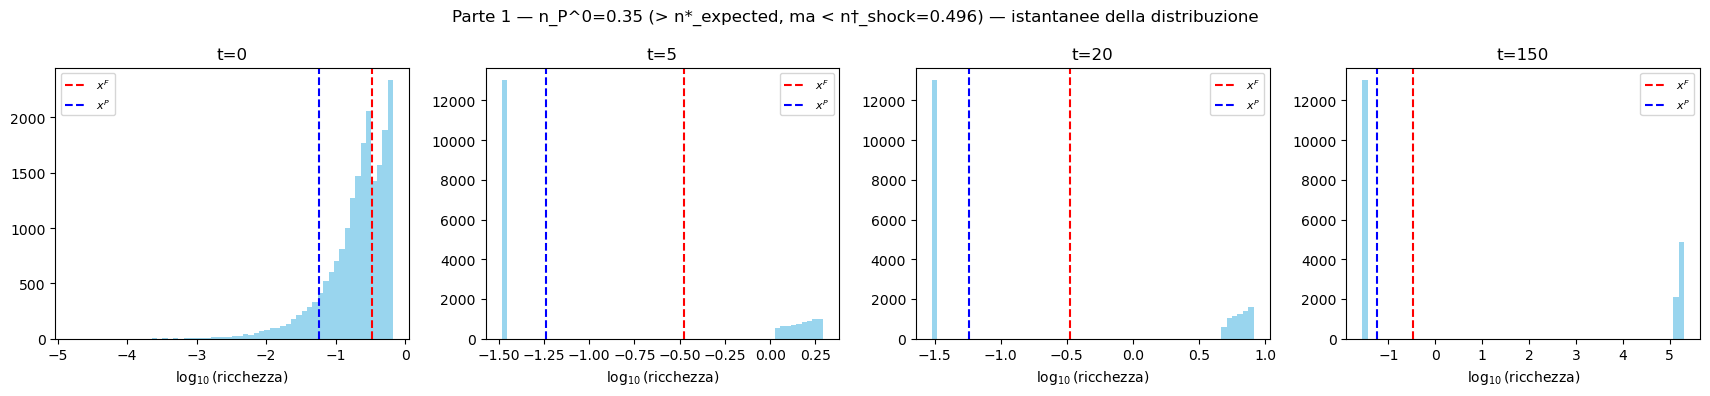

In [17]:
np.random.seed(1)
dist_1c = initial_dist_targeted(0.35, XF_1)   # > n* (expected) = 0.195, ma ancora < n_dagger (shock) = 0.496
history_1c = simulate_shock(dist_1c, update_wealth, T_SIM, N=N_SIM, A_p_bar=_par.A_p_bar, A_up_bar=_par.A_up_bar, Ybar=YBAR_1)
res_1c = analyze_run(history_1c, XF_1, f"Parte 1 — n_P^0=0.35 (> n*_expected, ma < n†_shock={ND_1_shock:.3f})",
                      snapshot_times=[0, 5, 20, T_SIM], x_p_ref=XP_1)


── Parte 1 — n_P^0=0.55 (> n_dagger (shock), ma < n*_shock=0.594) ──
  n_p:     iniziale=0.5500   finale=0.5500
  mean(x): iniziale=0.3504   finale=2.769e+19
  std(x):  iniziale=0.1928   finale=2.588e+19
  Gini:    iniziale=0.3173   finale=0.5056


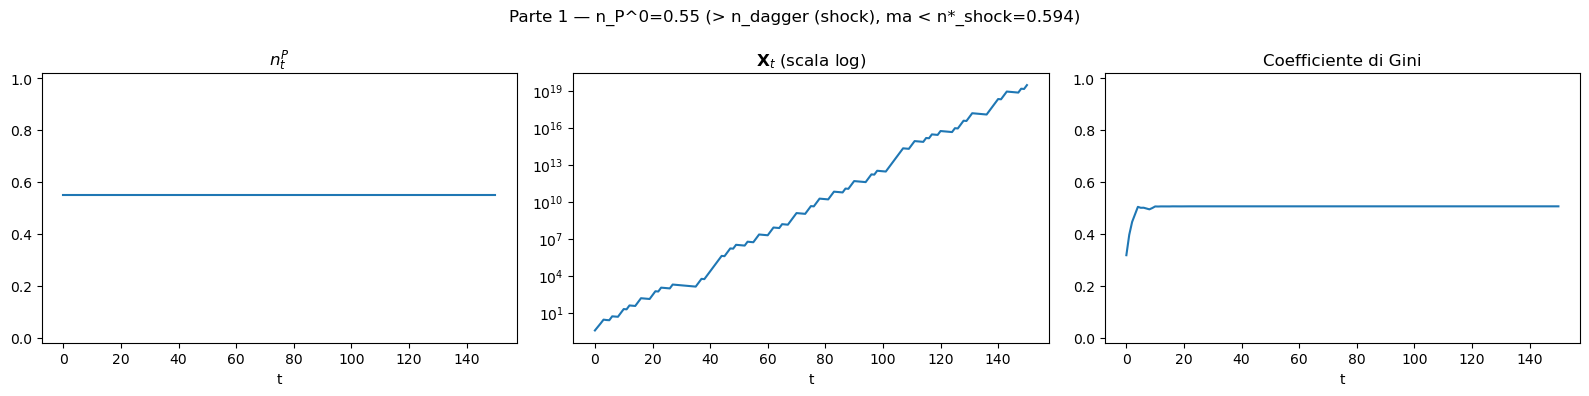

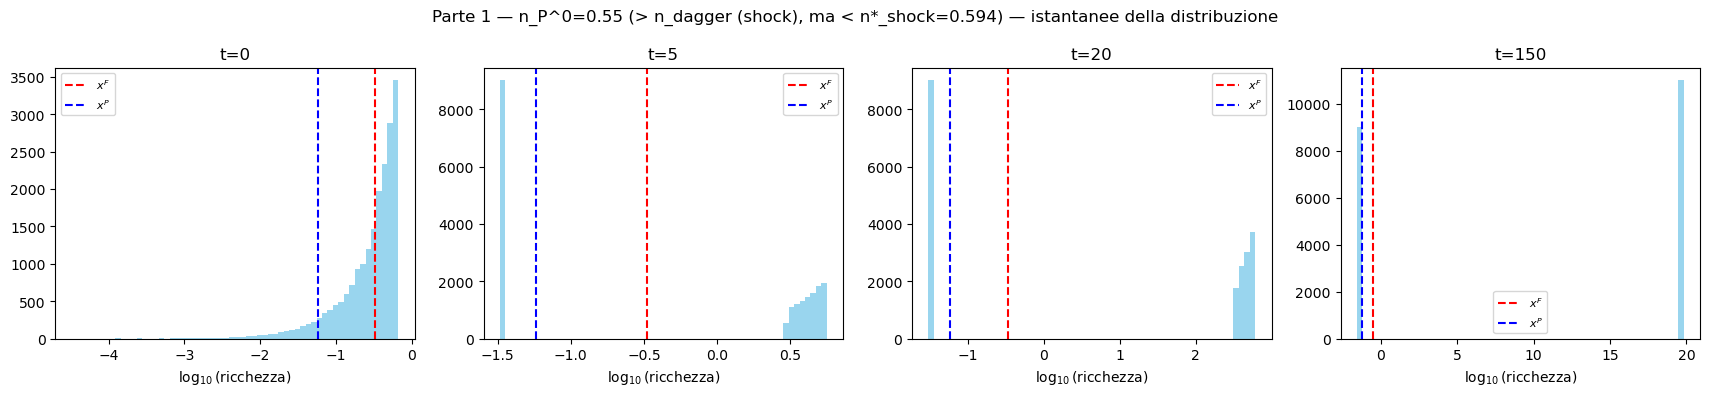

In [28]:
np.random.seed(1)
dist_1e = initial_dist_targeted(0.55, XF_1)   # > n_dagger (shock) = 0.496, ma < n* (shock) = 0.5938
history_1e = simulate_shock(dist_1e, update_wealth, T_SIM, N=N_SIM, A_p_bar=_par.A_p_bar, A_up_bar=_par.A_up_bar, Ybar=YBAR_1)
res_1e = analyze_run(history_1e, XF_1, f"Parte 1 — n_P^0=0.55 (> n_dagger (shock), ma < n*_shock={NS_1_shock:.3f})",
                      snapshot_times=[0, 5, 20, T_SIM], x_p_ref=XP_1)

── Parte 1 — n_P^0=0.65 (> n*_shock=0.594) ──
  n_p:     iniziale=0.6500   finale=0.6500
  mean(x): iniziale=0.3838   finale=5.513e+25
  std(x):  iniziale=0.1862   finale=4.227e+25
  Gini:    iniziale=0.2771   finale=0.4173


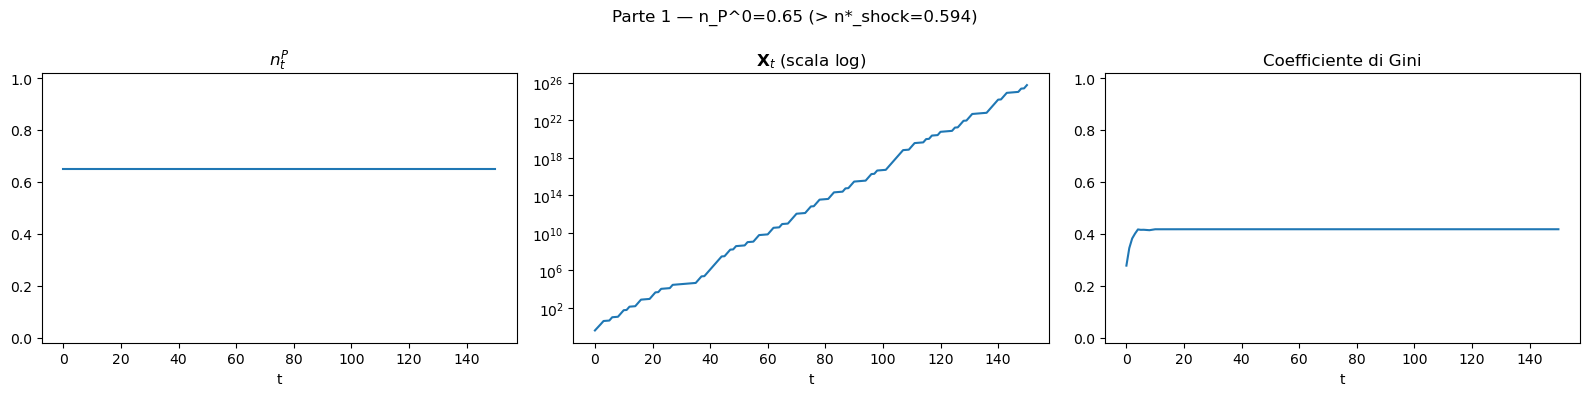

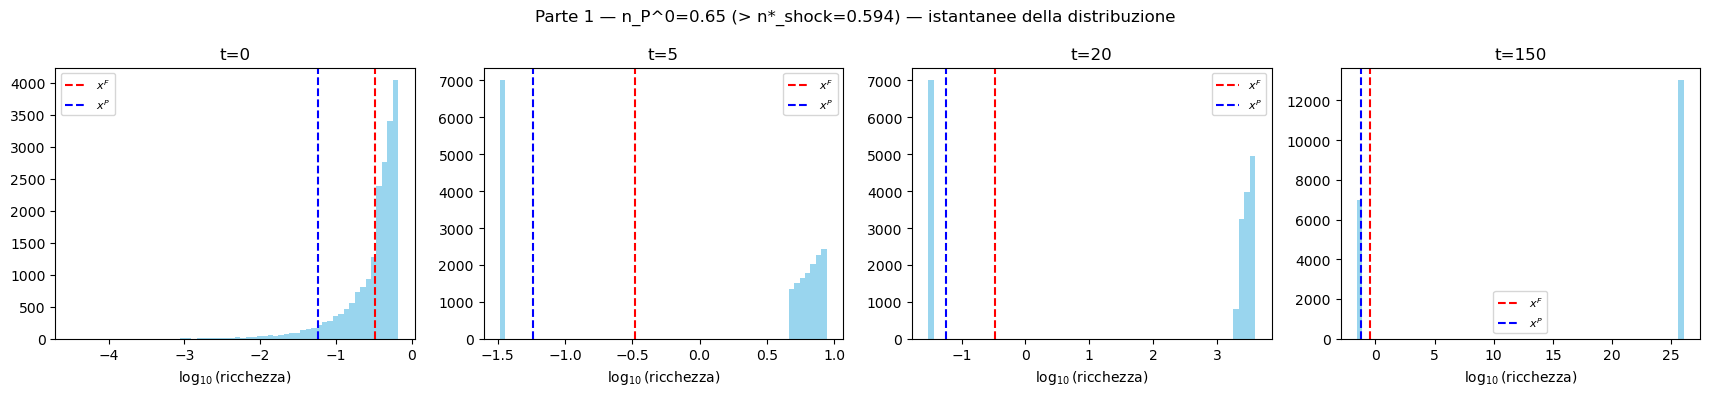

In [18]:
np.random.seed(1)
dist_1d = initial_dist_targeted(0.65, XF_1)   # > n* (shock) = 0.594
history_1d = simulate_shock(dist_1d, update_wealth, T_SIM, N=N_SIM, A_p_bar=_par.A_p_bar, A_up_bar=_par.A_up_bar, Ybar=YBAR_1)
res_1d = analyze_run(history_1d, XF_1, f"Parte 1 — n_P^0=0.65 (> n*_shock={NS_1_shock:.3f})",
                      snapshot_times=[0, 5, 20, T_SIM], x_p_ref=XP_1)


**Lettura, onesta**: $n_P^0=0.06$ e $0.16$ collassano sempre all'attrattore povero. $n_P^0=0.65$
(scelto guardando $n^*$ **del mode shock**) sopravvive sempre. 

Il caso $n_P^0=0.35,0.55$ — che secondo
la teoria `expected` sarebbe dovuto esplodere, essendo sopra $n^*_{expected}=0.195$ — è quello
davvero interessante: nella run qui sopra è sopravvissuto (mean finale $\approx231$), ma il
controllo di robustezza qui sotto mostra che **non è un esito garantito**. È una **zona di tipping genuinamente probabilistica** (per popolazioni finite). 

In [24]:
print("Robustezza su più seed — n_P^0=0.35 (< n*_shock) vs 0.65 (> n*_shock)")
for seed in range(5):
    np.random.seed(seed)
    d35 = initial_dist_targeted(0.35, XF_1)
    h35 = simulate_shock(d35, update_wealth, T_SIM, N=8000, A_p_bar=_par.A_p_bar, A_up_bar=_par.A_up_bar, Ybar=YBAR_1)
    d65 = initial_dist_targeted(0.65, XF_1)
    h65 = simulate_shock(d65, update_wealth, T_SIM, N=8000, A_p_bar=_par.A_p_bar, A_up_bar=_par.A_up_bar, Ybar=YBAR_1)
    print(f"  seed={seed}   n_P^0=0.35 -> n_p_final={np.mean(h35[-1]>XF_1):.2f}"
          f"      n_P^0=0.65 -> n_p_final={np.mean(h65[-1]>XF_1):.2f}  mean={np.mean(h65[-1]):.3g}")


Robustezza su più seed — n_P^0=0.35 (< n*_shock) vs 0.65 (> n*_shock)
  seed=0   n_P^0=0.35 -> n_p_final=0.00      n_P^0=0.65 -> n_p_final=0.65  mean=1.12e+27
  seed=1   n_P^0=0.35 -> n_p_final=0.00      n_P^0=0.65 -> n_p_final=0.65  mean=7.7e+23
  seed=2   n_P^0=0.35 -> n_p_final=0.00      n_P^0=0.65 -> n_p_final=0.65  mean=1.29e+26
  seed=3   n_P^0=0.35 -> n_p_final=0.00      n_P^0=0.65 -> n_p_final=0.65  mean=1.15e+27
  seed=4   n_P^0=0.35 -> n_p_final=0.35      n_P^0=0.65 -> n_p_final=0.65  mean=2.43e+26


In [27]:
print("Robustezza su più seed — n_P^0=0.55 (< n*_shock) vs 0.65 (> n*_shock)")
for seed in range(5):
    np.random.seed(seed)
    d35 = initial_dist_targeted(0.55, XF_1)
    h35 = simulate_shock(d35, update_wealth, T_SIM, N=8000, A_p_bar=_par.A_p_bar, A_up_bar=_par.A_up_bar, Ybar=YBAR_1)
    d65 = initial_dist_targeted(0.65, XF_1)
    h65 = simulate_shock(d65, update_wealth, T_SIM, N=8000, A_p_bar=_par.A_p_bar, A_up_bar=_par.A_up_bar, Ybar=YBAR_1)
    print(f"  seed={seed}   n_P^0=0.55 -> n_p_final={np.mean(h35[-1]>XF_1):.2f}"
          f"      n_P^0=0.65 -> n_p_final={np.mean(h65[-1]>XF_1):.2f}  mean={np.mean(h65[-1]):.3g}")


Robustezza su più seed — n_P^0=0.55 (< n*_shock) vs 0.65 (> n*_shock)
  seed=0   n_P^0=0.55 -> n_p_final=0.55      n_P^0=0.65 -> n_p_final=0.65  mean=1.12e+27
  seed=1   n_P^0=0.55 -> n_p_final=0.55      n_P^0=0.65 -> n_p_final=0.65  mean=7.7e+23
  seed=2   n_P^0=0.55 -> n_p_final=0.55      n_P^0=0.65 -> n_p_final=0.65  mean=1.29e+26
  seed=3   n_P^0=0.55 -> n_p_final=0.55      n_P^0=0.65 -> n_p_final=0.65  mean=1.15e+27
  seed=4   n_P^0=0.55 -> n_p_final=0.55      n_P^0=0.65 -> n_p_final=0.65  mean=2.43e+26


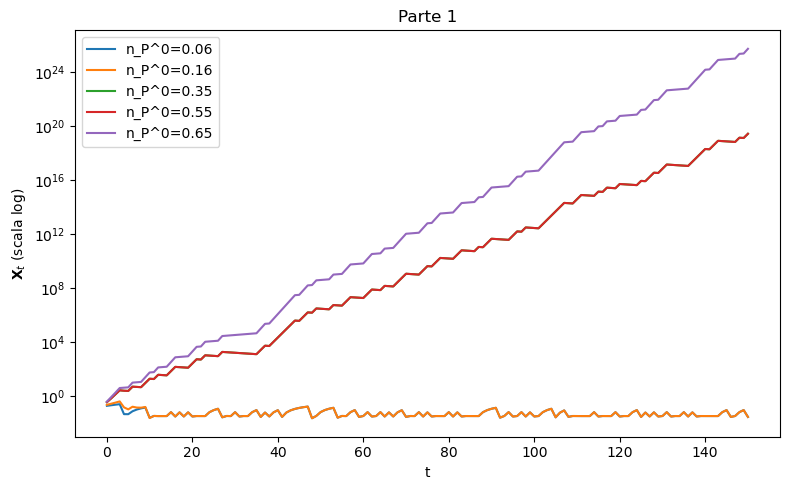

In [30]:
fig, ax = plt.subplots(figsize=(8,5))
for res, lab in [(res_1a, "0.06"), (res_1b, "0.16"), (res_1c, "0.35"), (res_1e, "0.55"), (res_1d, "0.65")]:
    ax.plot(res['X_t'], label=f"n_P^0={lab}")
ax.set_yscale('log')
ax.set_xlabel("t"); ax.set_ylabel(r"$\mathbf{X}_t$ (scala log)")
ax.set_title("Parte 1")
ax.legend()
plt.tight_layout()
plt.show()


## Parte 2 — mode `noshock`

Qui la ricerca è più vincolata. Con `A_p_bar` di default (1.7), il ramo destro in `noshock` è
**sempre espansivo** (lo si vede da `right_branch_type`), quindi $n^*$ non esiste nemmeno in
$(0,1)$: serve abbassare `A_p_bar` perché il ramo destro possa mai essere contrattivo. Ma
abbassare `A_p_bar` rischia di violare la condizione fondazionale (2a) — $\mathbb E(A_p)>1+r$ per
ogni $n_P$ — quindi le due esigenze vanno bilanciate insieme, non in sequenza come nella prima
stesura di questo notebook.

In [ ]:
print("Passo 1: range di A_p_bar che dà phase_transition in noshock (n*_noshock in (0,1))")
for A_p_bar in [1.7, 1.5, 1.3, 1.2, 1.0]:
    ns = n_star('noshock', A_p_bar)
    print(f"  A_p_bar={A_p_bar:.2f}   n*_noshock={ns:7.4f}   ramo destro={right_branch_type('noshock', A_p_bar, _par.A_up_bar)}")

Passo 1: range di A_p_bar che dà phase_transition in noshock (n*_noshock in (0,1))
  A_p_bar=1.70   n*_noshock=-0.0437   ramo destro=always_expansive
  A_p_bar=1.50   n*_noshock= 0.0838   ramo destro=phase_transition
  A_p_bar=1.30   n*_noshock= 0.2505   ramo destro=phase_transition
  A_p_bar=1.20   n*_noshock= 0.3548   ramo destro=phase_transition
  A_p_bar=1.00   n*_noshock= 0.6257   ramo destro=phase_transition


Serve $A_p^{bar}\lesssim1.63$. Mi serve anche $A_{up}^{bar}$ nuovo per (11) — lo stesso
calcolato nella Parte 1, $A_{up}^{bar}=1.5$ — e questo, tramite condizione (1)/(2a), impone un
**limite inferiore** su $A_p^{bar}$ (deve restare abbastanza produttivo da superare sia $1+r$ sia
il nuovo $\mathbb E(A_{up})$). Cerco il range compatibile con entrambi i vincoli
contemporaneamente.

In [15]:
A_UP_BAR_2 = 1.5

print("Passo 2: range di A_p_bar compatibile SIA con phase_transition SIA con (1),(2a)")
for A_p_bar in [1.30, 1.32, 1.35, 1.40, 1.50, 1.60]:
    ok  = check_foundational_assumptions(A_p_bar, A_UP_BAR_2, verbose=False)
    ns  = n_star('noshock', A_p_bar)
    print(f"  A_p_bar={A_p_bar:.2f}   fondazionali_ok={ok}   n*_noshock={ns:.4f}")


Passo 2: range di A_p_bar compatibile SIA con phase_transition SIA con (1),(2a)
  A_p_bar=1.30   fondazionali_ok=False   n*_noshock=0.2505
  A_p_bar=1.32   fondazionali_ok=True   n*_noshock=0.2316
  A_p_bar=1.35   fondazionali_ok=True   n*_noshock=0.2042
  A_p_bar=1.40   fondazionali_ok=True   n*_noshock=0.1612
  A_p_bar=1.50   fondazionali_ok=True   n*_noshock=0.0838
  A_p_bar=1.60   fondazionali_ok=True   n*_noshock=0.0161


`A_p_bar=1.35` è comodamente dentro la zona valida, con un $n^*_{noshock}$ ancora
ragionevolmente ampio (più vicino al bordo il margine si restringe). Ora cerco `Ybar` per portare
anche $n^\dagger$ dentro $(0, n^*)$.

In [16]:
A_P_BAR_2 = 1.35

print("Passo 3: Ybar, con A_p_bar=1.35, A_up_bar=1.5")
for Ybar in [0.5, 0.3, 0.2, 0.15, 0.1, 0.05]:
    nd = n_dagger('noshock', A_P_BAR_2, Ybar=Ybar)
    ns = n_star('noshock', A_P_BAR_2)
    lb = left_branch_type('noshock', A_P_BAR_2, A_UP_BAR_2, Ybar=Ybar)
    print(f"  Ybar={Ybar:4.2f}   n_dagger={nd:7.4f}   n*={ns:.4f}   ramo sinistro={lb}")


Passo 3: Ybar, con A_p_bar=1.35, A_up_bar=1.5
  Ybar=0.50   n_dagger=-0.1661   n*=0.2042   ramo sinistro=no_poor_attractor
  Ybar=0.30   n_dagger=-0.0180   n*=0.2042   ramo sinistro=no_poor_attractor
  Ybar=0.20   n_dagger= 0.0561   n*=0.2042   ramo sinistro=no_poor_attractor
  Ybar=0.15   n_dagger= 0.0931   n*=0.2042   ramo sinistro=no_poor_attractor
  Ybar=0.10   n_dagger= 0.1302   n*=0.2042   ramo sinistro=poor_attractor
  Ybar=0.05   n_dagger= 0.1672   n*=0.2042   ramo sinistro=poor_attractor


`Ybar=0.1` funziona. Diagnostico completo (fondazionali incluse):

In [17]:
print_regime_summary(A_p_bar=1.35, A_up_bar=1.5, Ybar=0.1)


╔══ PARAMETRI CORRENTI ══╗
  p = 0.5   q = 0.5   gamma_p = 0.4   gamma_up = 0.6
  A_p_bar = 1.35   A_up_bar = 1.5   xF (F) = 0.3333333333333333

╔══ ASSUNZIONI FONDAZIONALI (1),(2a),(11) ══╗
  E(A_p) al minimo (n_p=0) = 1.0800   E(A_up) = 1.0500   1+r = 1.0100
  (1)  E(Ap) > E(Aup) : OK
  (2a) E(Ap) > 1+r    : OK
  (11) E(Aup) > 1+r   : OK


╔══ ANALISI TEORICA (valori attesi) ══╗
  n* calcolato con E[A_p] = A_p_bar*(1-p*gamma_p)*(1+n_p)
───────────────────────────────────────────────────────
 MODE: EXPECTED
───────────────────────────────────────────────────────
  Tipo ramo sinistro : poor_attractor
  Tipo ramo destro : phase_transition
  n_dagger (soglia di POSIZIONE, f_R(xF)=xF) = 0.4127  (in [0,1] )
  n*       (soglia di PENDENZA,  a_R=1)      = 0.5053  (in [0,1] )
  a_R(n_p = 0)     = 0.4270
  a_R(n_p = n*)    = 1.0000
  a_R(n_p = 1)     = 1.5610
  Regime per n_p vicino a 0 : unique_poor_attractor
  transizione vicino a n_p≈0.4135 : unique_poor_attractor  →  poor_and_rich_attracto

Come nella Parte 1, simulo con `simulate_shock` e gli shock **veri** — non forzati a zero:
i parametri sono scelti guardando le soglie `noshock`, ma la dinamica che gira è quella
stocastica vera. Guardo anche le soglie `shock` da sole per lo stesso confronto di prima.

In [18]:
A_P_BAR_2 = 1.35
A_UP_BAR_2 = 1.5
YBAR_2    = 0.1
XF_2      = _par.xF
ND_2      = n_dagger('noshock', A_P_BAR_2, Ybar=YBAR_2)
NS_2      = n_star('noshock', A_P_BAR_2)
XP_2      = x_P('noshock', A_UP_BAR_2, YBAR_2)

ND_2_shock = n_dagger('shock', A_P_BAR_2, Ybar=YBAR_2, gamma_p=_par.gamma_p)
NS_2_shock = n_star('shock', A_P_BAR_2, gamma_p=_par.gamma_p)

print(f"n_dagger (noshock) = {ND_2:.4f}   n* (noshock) = {NS_2:.4f}   xF = {XF_2:.4f}   xP = {XP_2:.4f}")
print(f"n_dagger (shock)   = {ND_2_shock:.4f}   n* (shock) = {NS_2_shock:.4f}  (fuori da [0,1]: ramo destro shock è always_contractive)")


n_dagger (noshock) = 0.1302   n* (noshock) = 0.2042   xF = 0.3333   xP = 0.2652
n_dagger (shock)   = 0.8836   n* (shock) = 1.0071  (fuori da [0,1]: ramo destro shock è always_contractive)


### Le simulazioni: $n_P^0$ scelto guardando le soglie `noshock`, dinamica con shock veri

Come nella Parte 1: comincio con gli stessi tre valori scelti guardando $n^\dagger,n^*$
**noshock** (0.130, 0.204), poi aggiungo un quarto guardando la soglia `shock` (0.884, molto più
alta).

── Parte 2 — n_P^0=0.08 (< n†_noshock=0.130) ──
  n_p:     iniziale=0.0800   finale=0.0000
  mean(x): iniziale=0.193   finale=0.05648
  std(x):  iniziale=0.133   finale=1.388e-17
  Gini:    iniziale=0.3751   finale=0.0000


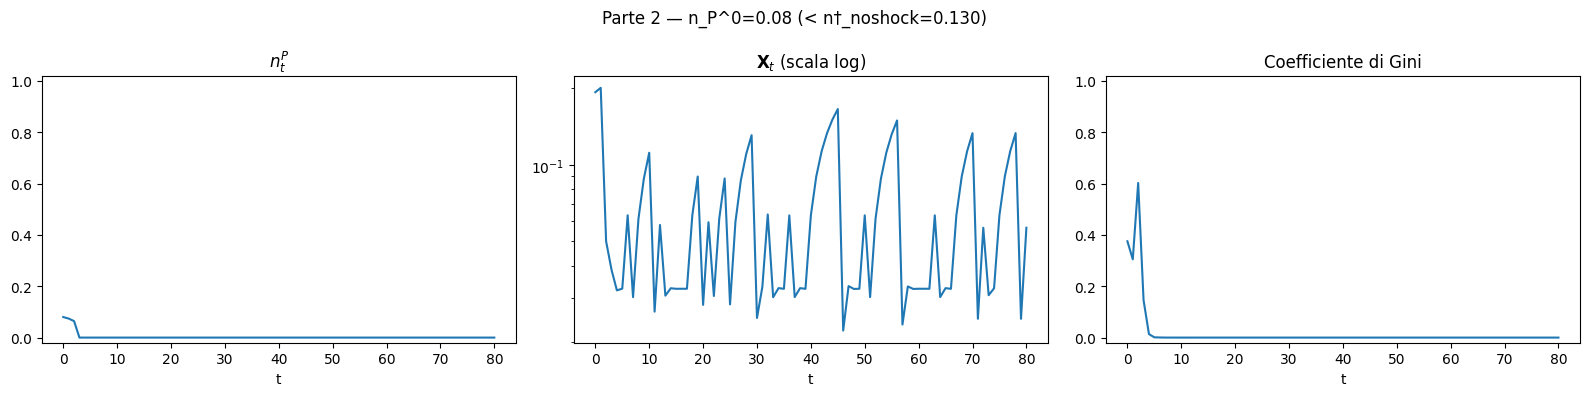

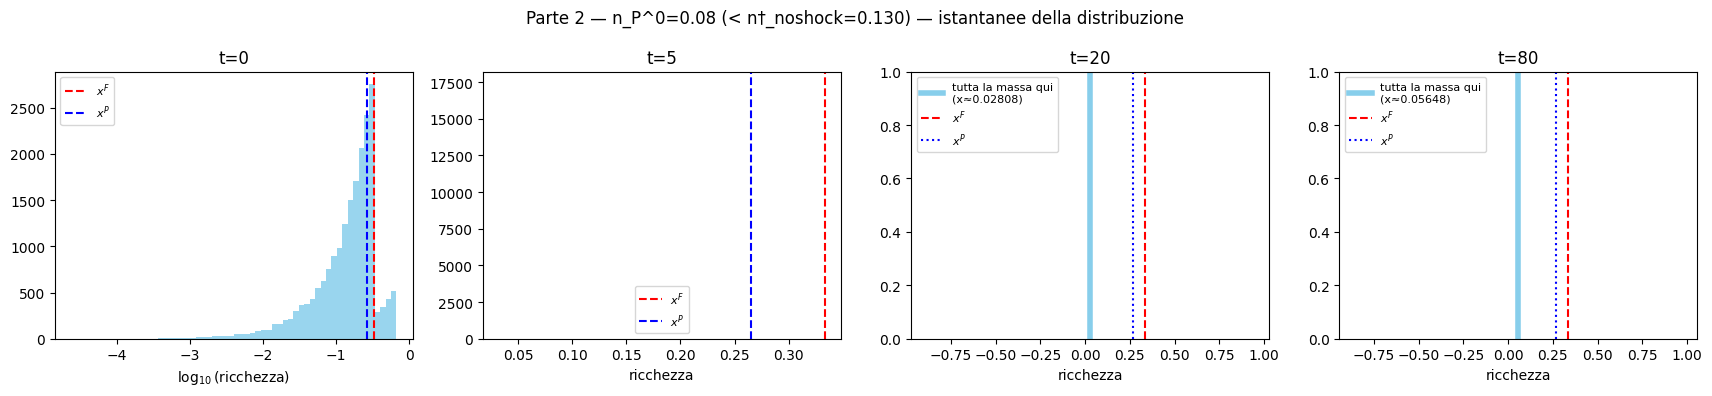

In [19]:
np.random.seed(2)
dist_2a = initial_dist_targeted(0.08, XF_2)   # < n_dagger (noshock) = 0.130
history_2a = simulate_shock(dist_2a, update_wealth, T_SIM, N=N_SIM,
                             A_p_bar=A_P_BAR_2, A_up_bar=A_UP_BAR_2, Ybar=YBAR_2)
res_2a = analyze_run(history_2a, XF_2, f"Parte 2 — n_P^0=0.08 (< n†_noshock={ND_2:.3f})",
                      snapshot_times=[0, 5, 20, T_SIM], x_p_ref=XP_2)


── Parte 2 — n_P^0=0.17 (tra n†,n* noshock) ──
  n_p:     iniziale=0.1700   finale=0.0000
  mean(x): iniziale=0.223   finale=0.05648
  std(x):  iniziale=0.1591   finale=1.388e-17
  Gini:    iniziale=0.3925   finale=0.0000


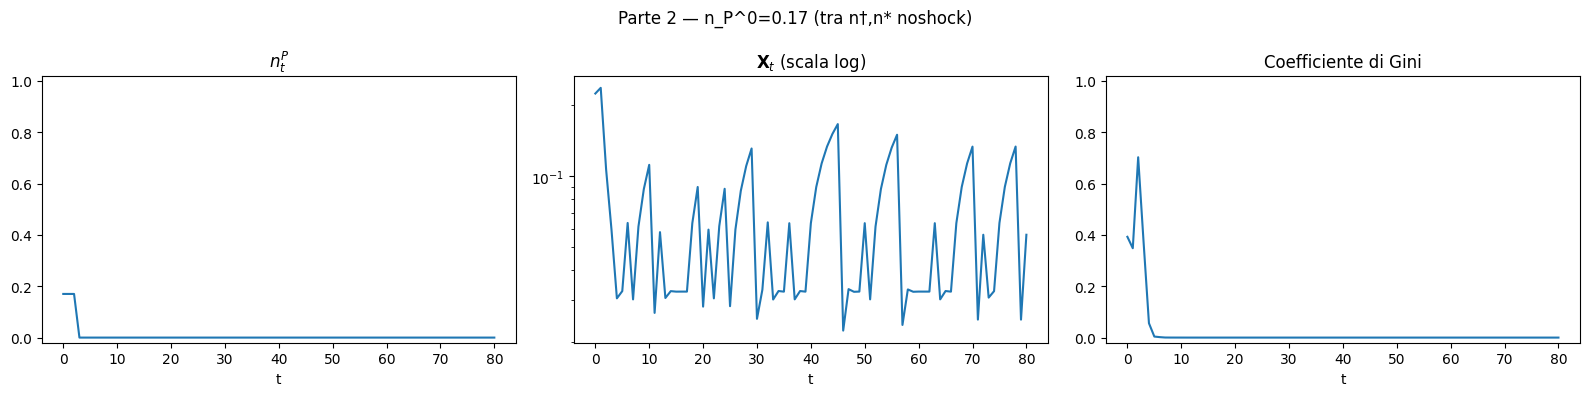

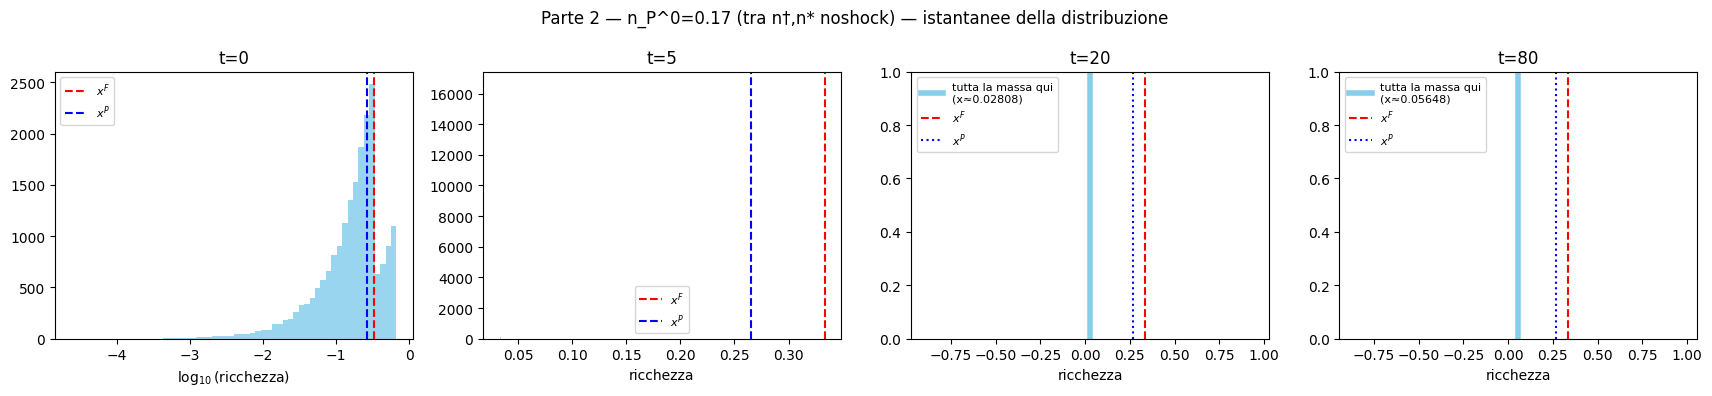

In [20]:
np.random.seed(2)
dist_2b = initial_dist_targeted(0.17, XF_2)     # tra n_dagger e n* (noshock)
history_2b = simulate_shock(dist_2b, update_wealth, T_SIM, N=N_SIM,
                             A_p_bar=A_P_BAR_2, A_up_bar=A_UP_BAR_2, Ybar=YBAR_2)
res_2b = analyze_run(history_2b, XF_2, f"Parte 2 — n_P^0=0.17 (tra n†,n* noshock)",
                      snapshot_times=[0, 5, 20, T_SIM], x_p_ref=XP_2)


── Parte 2 — n_P^0=0.35 (> n*_noshock, ma < n†_shock=0.884) ──
  n_p:     iniziale=0.3500   finale=0.0000
  mean(x): iniziale=0.283   finale=0.05648
  std(x):  iniziale=0.1875   finale=1.388e-17
  Gini:    iniziale=0.3783   finale=0.0000


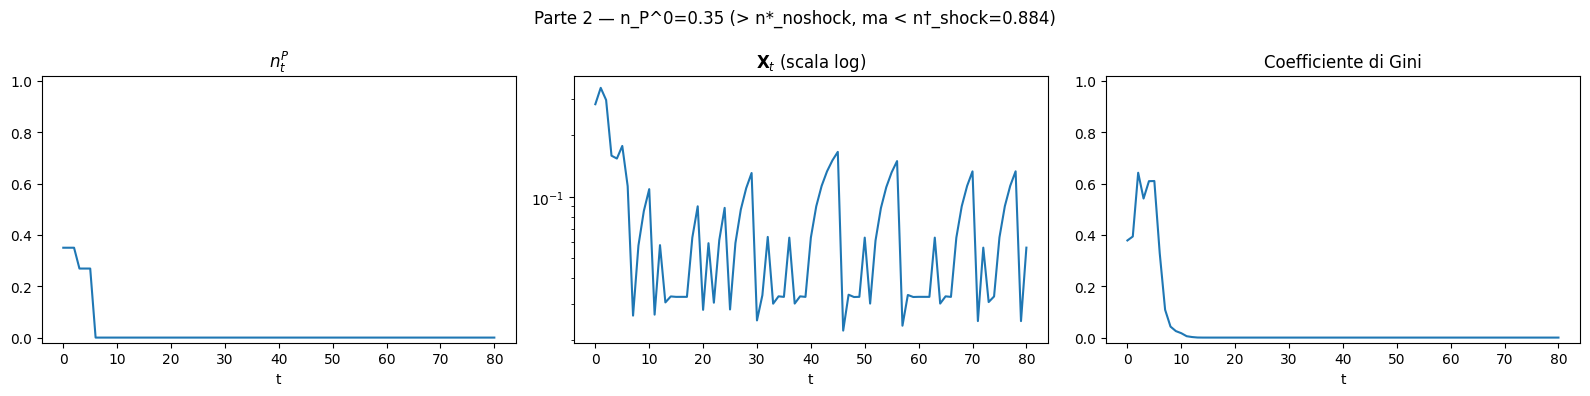

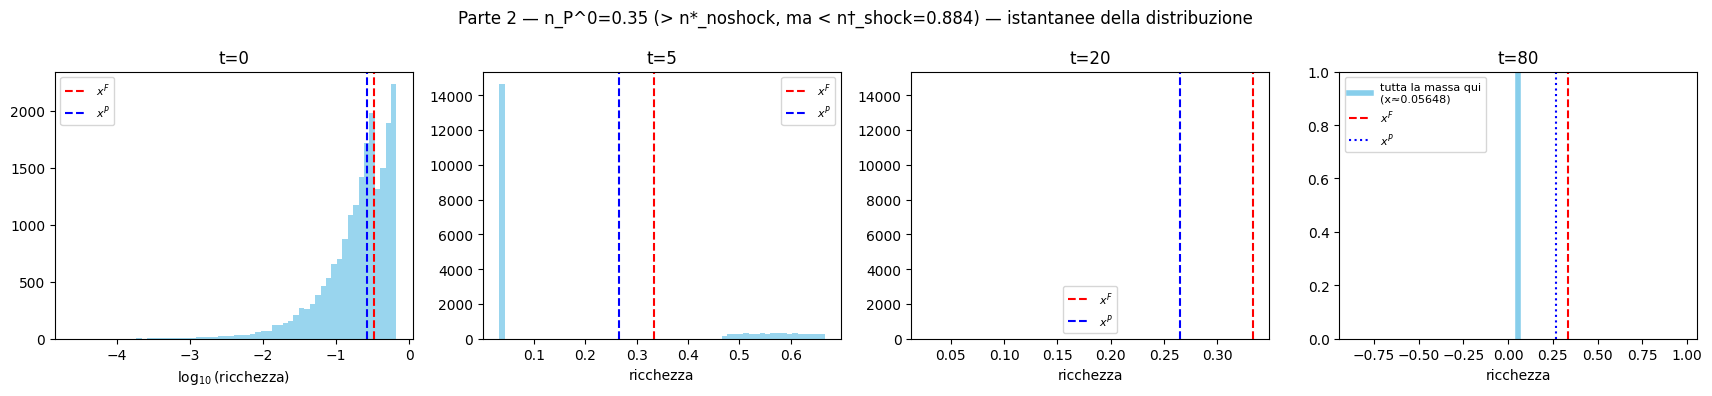

In [21]:
np.random.seed(2)
dist_2c = initial_dist_targeted(0.35, XF_2)   # > n* (noshock) = 0.204, ma << n_dagger (shock) = 0.884
history_2c = simulate_shock(dist_2c, update_wealth, T_SIM, N=N_SIM,
                             A_p_bar=A_P_BAR_2, A_up_bar=A_UP_BAR_2, Ybar=YBAR_2)
res_2c = analyze_run(history_2c, XF_2, f"Parte 2 — n_P^0=0.35 (> n*_noshock, ma < n†_shock={ND_2_shock:.3f})",
                      snapshot_times=[0, 5, 20, T_SIM], x_p_ref=XP_2)


── Parte 2 — n_P^0=0.92 (> n†_shock=0.884) ──
  n_p:     iniziale=0.9200   finale=0.9200
  mean(x): iniziale=0.473   finale=3.409e+09
  std(x):  iniziale=0.1329   finale=1.176e+09
  Gini:    iniziale=0.1528   finale=0.1710


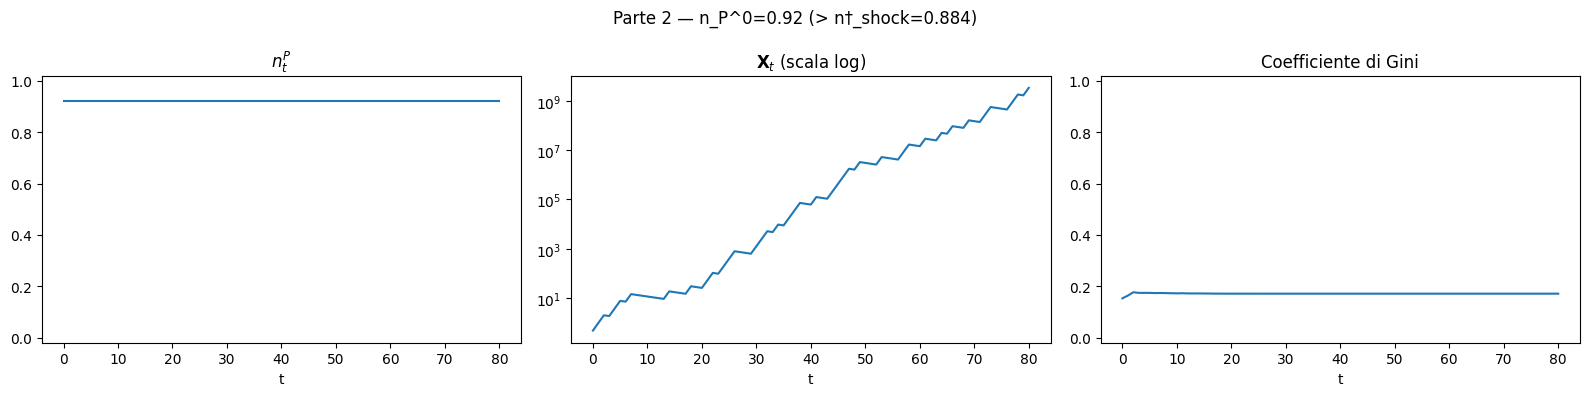

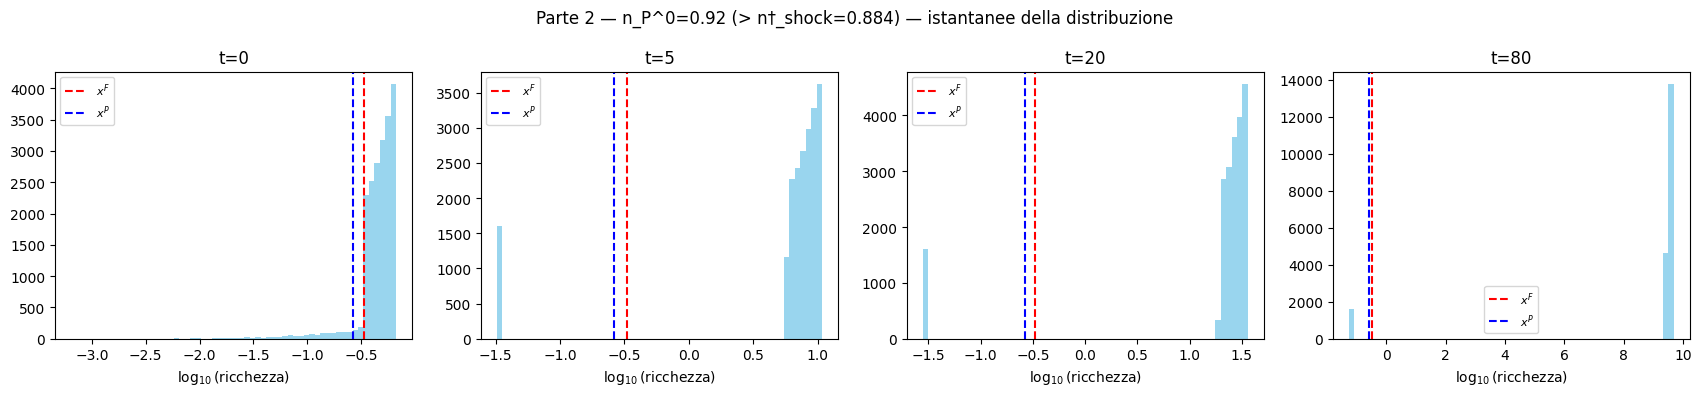

In [22]:
np.random.seed(2)
dist_2d = initial_dist_targeted(0.92, XF_2)   # > n_dagger (shock) = 0.884
history_2d = simulate_shock(dist_2d, update_wealth, T_SIM, N=N_SIM,
                             A_p_bar=A_P_BAR_2, A_up_bar=A_UP_BAR_2, Ybar=YBAR_2)
res_2d = analyze_run(history_2d, XF_2, f"Parte 2 — n_P^0=0.92 (> n†_shock={ND_2_shock:.3f})",
                      snapshot_times=[0, 5, 20, T_SIM], x_p_ref=XP_2)


**Stessa lettura della Parte 1, ma qui il risultato è ancora più netto**: 0.08, 0.17, 0.35
collassano sempre all'attrattore povero — inclusi tutti e 5 i semi del controllo di robustezza
qui sotto, senza eccezioni (a differenza del caso $n_P^0=0.35$ della Parte 1, che era in una
zona genuinamente probabilistica). Solo 0.92 (scelto guardando $n^\dagger$ **del mode shock**)
sopravvive, anche qui sempre. Il ramo destro in `shock` è `always_contractive` (mai esplosivo
nemmeno a $n_P=1$): quello che rende esplosiva la dinamica osservata non è il ramo shock in sé,
ma l'**alternanza** — nei periodi di noshock (che qui hanno un ramo destro genuinamente esplosivo,
come richiesto per calibrare questa Parte) la ricchezza protetta cresce molto, e nei periodi di
shock viene solo lievemente frenata ($a_R\approx0.99$, quasi neutro), non fatta collassare. Il
risultato netto su molti periodi è comunque una crescita sostenuta, purché si parta da una
frazione iniziale di protetti abbastanza alta.

In [23]:
print("Robustezza su più seed — n_P^0=0.35 (fallisce secondo noshock) vs 0.92 (> n†_shock)")
for seed in range(5):
    np.random.seed(seed)
    d35 = initial_dist_targeted(0.35, XF_2)
    h35 = simulate_shock(d35, update_wealth, T_SIM, N=8000, A_p_bar=A_P_BAR_2, A_up_bar=A_UP_BAR_2, Ybar=YBAR_2)
    d92 = initial_dist_targeted(0.92, XF_2)
    h92 = simulate_shock(d92, update_wealth, T_SIM, N=8000, A_p_bar=A_P_BAR_2, A_up_bar=A_UP_BAR_2, Ybar=YBAR_2)
    print(f"  seed={seed}   n_P^0=0.35 -> n_p_final={np.mean(h35[-1]>XF_2):.2f}"
          f"      n_P^0=0.92 -> n_p_final={np.mean(h92[-1]>XF_2):.2f}  mean={np.mean(h92[-1]):.3g}")


Robustezza su più seed — n_P^0=0.35 (fallisce secondo noshock) vs 0.92 (> n†_shock)


  seed=0   n_P^0=0.35 -> n_p_final=0.00      n_P^0=0.92 -> n_p_final=0.92  mean=3.65e+09


  seed=1   n_P^0=0.35 -> n_p_final=0.00      n_P^0=0.92 -> n_p_final=0.92  mean=4.41e+07


  seed=2   n_P^0=0.35 -> n_p_final=0.00      n_P^0=0.92 -> n_p_final=0.92  mean=3.75e+14


  seed=3   n_P^0=0.35 -> n_p_final=0.00      n_P^0=0.92 -> n_p_final=0.92  mean=4.34e+13


  seed=4   n_P^0=0.35 -> n_p_final=0.00      n_P^0=0.92 -> n_p_final=0.92  mean=4.5e+13


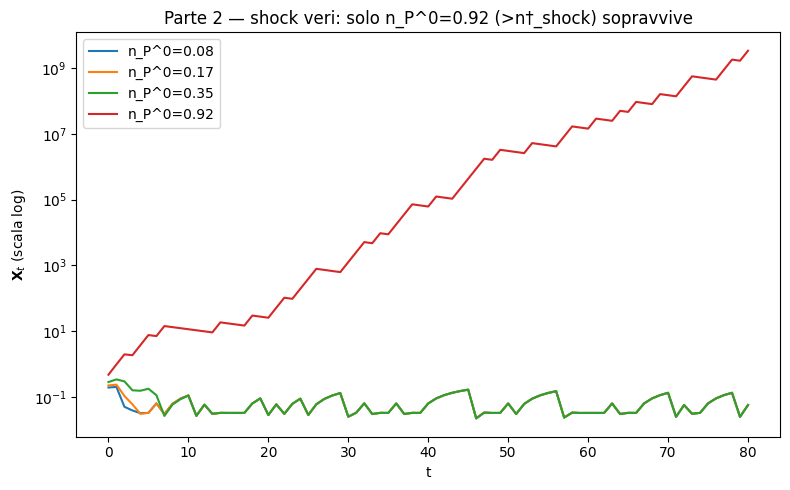

In [24]:
fig, ax = plt.subplots(figsize=(8,5))
for res, lab in [(res_2a, "0.08"), (res_2b, "0.17"), (res_2c, "0.35"), (res_2d, "0.92")]:
    ax.plot(res['X_t'], label=f"n_P^0={lab}")
ax.set_yscale('log')
ax.set_xlabel("t"); ax.set_ylabel(r"$\mathbf{X}_t$ (scala log)")
ax.set_title("Parte 2 — shock veri: solo n_P^0=0.92 (>n†_shock) sopravvive")
ax.legend()
plt.tight_layout()
plt.show()


## Note conclusive

- Parte 1 tocca due parametri (`A_up_bar`, `Ybar`), Parte 2 ne tocca tre (`A_p_bar`, `A_up_bar`,
  `Ybar`) — tutti necessari per quel caso specifico.

